<a href="https://colab.research.google.com/github/ZZZeet/qwen3-inference-experiments/blob/main/inference_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Qwen3-0.6B Inference Experiments


## Environment Setup

This benchmark runs on Google Colab with an NVIDIA T4 GPU, Python 3.12, PyTorch 2.7.1 (CUDA 12.8), and Transformers 4.53.3. The model runs in FP16.

In [1]:
!python --version
!nvidia-smi

Python 3.12.13
Wed Nov 25 18:35:49 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+--------------------------------

## Model and Test Data

We use Qwen3-0.6B with a LoRA adapter and 900 SQuAD 1.1 test questions.

In [2]:
!git clone https://github.com/sunweiyi2026-ship-it/LLM-project.git
%cd /content/LLM-project

!python -m pip install torch==2.7.1 torchvision==0.22.1 torchaudio==2.7.1 --index-url https://download.pytorch.org/whl/cu128
!python -m pip install -e .

!python -m genqa pretrained --verify-only

Cloning into 'LLM-project'...
remote: Enumerating objects: 149, done.
remote: Counting objects: 100% (149/149), done.
remote: Compressing objects: 100% (136/136), done.
remote: Total 149 (delta 50), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (149/149), 20.68 MiB | 10.81 MiB/s, done.
Resolving deltas: 100% (50/50), done.
/content/LLM-project
Looking in indexes: https://download.pytorch.org/whl/cu128
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 75.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 97.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 108.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 726.9/726.9 MB 24.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 609.6/609.6 MB 71.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 59.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 144.4 MB/s eta 0:00:00
     ━━

Note: Restart session if cannot find `genqa` below.

In [1]:
# make sure environment variables are in place
%cd /content/LLM-project

import sys
sys.path.insert(0, "/content/LLM-project/src")

import genqa
print(genqa.__file__)

import numpy as np
import numpy.strings
print(np.__version__)

/content/LLM-project
/content/LLM-project/src/genqa/__init__.py
2.2.6


### Timing and visualization helpers

These functions time synchronized generation, collect peak GPU allocations, summarize batch measurements, and plot the results.

In [2]:
import json
import shutil
from datetime import datetime, timezone
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import GenerationConfig

from genqa.engine import prepare_input, score_answer


def measure_batch(model, inputs, generation, device):
    torch.cuda.synchronize(device)
    baseline = torch.cuda.memory_allocated(device)
    torch.cuda.reset_peak_memory_stats(device)

    start = perf_counter()
    with torch.inference_mode():
        output = model.generate(
            **inputs, generation_config=generation, use_model_defaults=False
        )
    torch.cuda.synchronize(device)
    elapsed = perf_counter() - start
    peak = torch.cuda.max_memory_allocated(device)

    token_ids = output[:, inputs["input_ids"].shape[1]:].tolist()
    return elapsed, peak / 2**20, (peak - baseline) / 2**20, token_ids


def summarize_batches(batches):
    return (
        batches.groupby("kv_cache", sort=False)
        .agg(
            n_timed_batches=("generate_seconds", "size"),
            n_timed_questions=("n_questions", "sum"),
            total_generate_s=("generate_seconds", "sum"),
            median_batch_ms=("generate_seconds", lambda x: x.median() * 1000),
            p95_batch_ms=("generate_seconds", lambda x: x.quantile(0.95) * 1000),
            peak_allocated_mib=("peak_allocated_mib", "max"),
            peak_extra_allocated_mib=("extra_allocated_mib", "max"),
        )
        .assign(questions_per_s=lambda x: x.n_timed_questions / x.total_generate_s)
    )

def plot_results(summary, pairs, destination):
    figure = plt.figure(figsize=(13, 8), layout="constrained")
    grid = figure.add_gridspec(2, 6)

    throughput_ax = figure.add_subplot(grid[0, 0:2])
    peak_memory_ax = figure.add_subplot(grid[0, 2:4])
    speedup_ax = figure.add_subplot(grid[0, 4:6])
    total_time_ax = figure.add_subplot(grid[1, 1:3])
    extra_memory_ax = figure.add_subplot(grid[1, 3:5])

    modes = ["off", "on"]
    colors = ["#8391a6", "#176b79"]
    for axis, column, title, unit in (
        (throughput_ax, "questions_per_s", "Generation throughput", "Questions / s"),
        (peak_memory_ax, "peak_allocated_mib", "Peak allocated GPU memory", "MiB"),
        (total_time_ax, "total_generate_s", "Total generation time", "Seconds"),
        (extra_memory_ax, "peak_extra_allocated_mib", "Peak extra allocated GPU memory", "MiB"),
    ):
        values = summary.loc[modes, column]
        bars = axis.bar(["Cache off", "Cache on"], values, color=colors, width=0.58)
        axis.bar_label(bars, fmt="%.2f", padding=4)
        axis.set(title=title, ylabel=unit, ylim=(0, values.max() * 1.18))
        axis.grid(axis="y", alpha=0.2)
        axis.set_axisbelow(True)

    median_pairs = pairs.groupby("batch_id", as_index=False).agg(
        padded_prompt_tokens_per_sequence=("padded_prompt_tokens_per_sequence", "first"),
        speedup=("speedup_off_over_on", "median"),
    )
    speedup_ax.scatter(
        median_pairs["padded_prompt_tokens_per_sequence"], median_pairs["speedup"],
        color=colors[1], alpha=0.6, s=18,
    )
    speedup_ax.axhline(1, color=colors[0], linestyle="--")
    speedup_ax.set(
        title="Cache speedup by prompt length",
        xlabel="Padded prompt tokens per question",
        ylabel="Batch time off / on",
    )
    speedup_ax.grid(alpha=0.2)

    figure.savefig(destination, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)

### Check `bundle` is loaded

In [3]:
import os
import sys
from pathlib import Path

repo_root = Path("/content/LLM-project")

if "bundle" not in globals():
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    from genqa.pretrained import load_published_model

    bundle = load_published_model(root=str(repo_root))

模型缓存缺少 8 个文件；下载固定修订 c1899de289a04d12100db370d81485cdf75e47ca 到 /content/LLM-project/cache/model


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

... (2 outputs left out)

vocab.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.50G [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

模型 8 个文件 SHA256 校验通过：/content/LLM-project/cache/model


## Experiment 1 — KV Cache BenchmarkKV Cache Benchmark

We run the same batches with the KV cache enabled and disabled. Each batch contains four questions, and each setting is tested three times.

The code chunk below is a smoke test to ensure that KV cache switch works.

In [ ]:
# smoke testing that KV cache switch works
import os

# config before first time using CUDA in the notebook
if "bundle" not in globals():
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    from genqa.pretrained import load_published_model

    bundle = load_published_model(root=str(repo_root))

import torch
from transformers import GenerationConfig
from genqa.engine import prepare_input
from genqa.pretrained import load_published_model

model, tokenizer = bundle["model"], bundle["tokenizer"]
settings = bundle["spec"]["evaluation"]

batch_size = 4                       # change here to test different batch size
rows = bundle["rows"]["test"][:batch_size]

tokenizer.padding_side = "left"
inputs = tokenizer.pad(
    [
        {"input_ids": prepare_input(
            row, tokenizer, bundle["prompt"], settings["max_input_tokens"]
        )["input_ids"]}
        for row in rows
    ],
    padding=True,
    return_tensors="pt",
).to("cuda")

for use_cache in (True, False):
    generation = GenerationConfig(
        use_cache=use_cache,         # KV cache switch
        do_sample=False,             # greedy decoding
        num_beams=1,
        max_new_tokens=settings["max_new_tokens"],
        eos_token_id=model.generation_config.eos_token_id,
        pad_token_id=tokenizer.pad_token_id,
    )

    with torch.inference_mode():
        output = model.generate(
            **inputs, generation_config=generation, use_model_defaults=False
        )

    answer_ids = output[:, inputs["input_ids"].shape[1]:]
    print(f"use_cache={use_cache}")
    print(tokenizer.batch_decode(answer_ids, skip_special_tokens=True))

模型缓存缺少 8 个文件；下载固定修订 c1899de289a04d12100db370d81485cdf75e47ca 到 /content/LLM-project/cache/model


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

模型 8 个文件 SHA256 校验通过：/content/LLM-project/cache/model


You're using a Qwen2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


use_cache=True
['over 18 million', '2003', 'Western art from the Middle Ages to the present emphasizing Italian early Renaissance, British pre-Raphaelite, and 19th-century French art', 'half a mile northwest']
use_cache=False
['over 18 million', '2003', 'Western art from the Middle Ages to the present emphasizing Italian early Renaissance, British pre-Raphaelite, and 19th-century French art', 'half a mile northwest']


### **Research question**

How does enabling the KV cache affect generation speed, peak GPU memory, and answer quality for Qwen3-0.6B + LoRA on the MRQA 2019 SQuAD 1.1 test set?

### **Hypotheses**

- **Speed.** I expect enabling the KV cache to increase overall generation throughput by at least 20%. I also expect larger speedups for batches with longer prompts, because each decoding step can reuse the keys and values computed for earlier tokens. Since most answers are short, the initial prompt processing may account for a substantial share of the total generation time.
- **Answer quality.** I expect at least 99% of decoded answers to match exactly across the two settings, with EM and F1 each differing by less than one percentage point.
- **Memory.** I suppose storing the cache raises peak GPU memory.

### **Experimental setup**

I will first run a 32-question pilot to verify the benchmark. For the formal experiment, I will run all 900 test questions three times on the same Colab T4 GPU in FP16. Each batch will run with the cache enabled and disabled. I will keep the model, prompts, batch size of 4, and generation limit of 64 new tokens fixed. I will warm up both settings and alternate which one runs first within each batch.

### **Measurements and visualization**

I will report generation throughput in questions per second, median and 95th-percentile batch latency, peak GPU memory allocated by PyTorch, and answer quality using exact match (EM), token-level F1, and answer agreement. Timing covers `model.generate()`, including prompt processing and decoding, with the inputs already on the GPU.

Speedup is the cache-off time divided by the cache-on time, so a value above 1 means that enabling the cache was faster.
$$
\mathrm{Speedup} = \frac{T_{\mathrm{cache\ off}}}{T_{\mathrm{cache\ on}}}
$$


### Benchmark

Each batch is measured with both cache settings. The benchmark exports batch timings, per-question answers, a metric summary, and a figure. The paired speedup is the cache-off batch time divided by the cache-on batch time. Values above 1 favor enabling the cache.

In [ ]:
def run_kv_cache_benchmark(
    bundle, *, limit=None, repeats=3, batch_size=None, output_root="/content/kv_cache_results"
):
    """Run paired cache-on/off trials. A limit samples a fixed subset for a pilot."""
    model, tokenizer = bundle["model"], bundle["tokenizer"]
    settings = bundle["spec"]["evaluation"]
    published_rows = bundle["rows"]["test"]
    batch_size = settings["batch_size"] if batch_size is None else batch_size
    if repeats < 1 or batch_size < 1 or (limit is not None and not 1 <= limit <= len(published_rows)):
        raise ValueError("Use positive repeats and batch_size, and a limit within the test set.")

    device = next(model.parameters()).device
    if device.type != "cuda":
        raise ValueError("Load the published model on a CUDA GPU before running the benchmark.")
    model.eval()

    if limit is None:
        rows = published_rows
    else:
        indices = np.random.default_rng(17).choice(len(published_rows), size=limit, replace=False)
        rows = [published_rows[int(index)] for index in sorted(indices)]
    prepared = [
        (row, prepare_input(row, tokenizer, bundle["prompt"], settings["max_input_tokens"]))
        for row in rows
    ]
    prepared.sort(key=lambda item: (item[1]["input_tokens"], item[0].get("dataset", "SQuAD"), item[0]["id"]))
    batches = [prepared[i:i + batch_size] for i in range(0, len(prepared), batch_size)]

    tokenizer.padding_side = "left"
    eos = model.generation_config.eos_token_id
    eos_ids = set(eos if isinstance(eos, (list, tuple)) else [eos])
    generations = {
        mode: GenerationConfig(
            do_sample=False, num_beams=1, max_new_tokens=settings["max_new_tokens"],
            use_cache=(mode == "on"), eos_token_id=eos, pad_token_id=tokenizer.pad_token_id,
            repetition_penalty=1.0,
        )
        for mode in ("off", "on")
    }

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    output_dir = Path(output_root) / stamp
    output_dir.mkdir(parents=True, exist_ok=False)
    metadata = {
        "status": "running",
        "split": "test",
        "test_questions": len(rows),
        "published_test_questions": len(published_rows),
        "pilot_limit": limit,
        "subset_seed": 17 if limit is not None else None,
        "repeats": repeats,
        "batch_size": batch_size,
        "gpu": torch.cuda.get_device_name(device),
        "model_dtype": str(next(model.parameters()).dtype),
        "torch": str(torch.__version__),
        "cuda_build": torch.version.cuda,
        "model_revision": bundle.get("verification", {}).get("model_revision"),
        "publication_manifest_sha256": bundle.get("verification", {}).get("manifest_sha256"),
        "max_input_tokens": settings["max_input_tokens"],
        "max_new_tokens": settings["max_new_tokens"],
        "generation": {mode: config.to_dict() for mode, config in generations.items()},
        "timing_scope": "Synchronized wall time for generate, including prefill and decoding.",
        "memory_scope": "PyTorch peak live CUDA allocations, including resident model and inputs.",
        "batch_order": "Sorted by prompt tokens. Cache mode measured first alternates by batch and repeat.",
    }
    metadata_path = output_dir / "run_config.json"
    metadata_path.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

    def encode(batch):
        return tokenizer.pad(
            [{"input_ids": data["input_ids"]} for _, data in batch],
            padding=True, return_tensors="pt",
        ).to(device)

    # Warm up on short, middle, and long inputs before collecting timings.
    for index in sorted({0, len(batches) // 2, len(batches) - 1}):
        warm_inputs = encode(batches[index])
        for mode in ("on", "off"):
            measure_batch(model, warm_inputs, generations[mode], device)
        del warm_inputs

    timing_rows = []
    predictions = {}
    repeat_mismatches = {"off": 0, "on": 0}
    for repeat in range(1, repeats + 1):
        for batch_id, batch in enumerate(batches, 1):
            inputs = encode(batch)
            modes = ("on", "off") if (repeat + batch_id) % 2 == 0 else ("off", "on")
            for order, mode in enumerate(modes, 1):
                elapsed, peak, extra, sequences = measure_batch(model, inputs, generations[mode], device)
                output_lengths = []
                for (row, data), tokens in zip(batch, sequences, strict=True):
                    stop = next((i for i, token in enumerate(tokens) if token in eos_ids), len(tokens))
                    answer_ids = tokens[:stop]
                    output_lengths.append(min(stop + 1, len(tokens)))
                    text = tokenizer.decode(answer_ids, skip_special_tokens=True).strip()
                    key = (mode, row["id"])
                    if repeat == 1:
                        scores = score_answer(text, row["answers"])
                        predictions[key] = {
                            "question_id": row["id"], "kv_cache": mode, "batch_id": batch_id,
                            "input_tokens": data["input_tokens"], "output_tokens": output_lengths[-1],
                            "generation_capped": stop == len(tokens) and len(tokens) >= settings["max_new_tokens"],
                            "answer": text, "em_pct": scores["em"], "f1_pct": scores["f1"],
                        }
                    else:
                        repeat_mismatches[mode] += text != predictions[key]["answer"]

                timing_rows.append({
                    "repeat": repeat, "batch_id": batch_id, "kv_cache": mode,
                    "order_in_pair": order, "n_questions": len(batch),
                    "padded_prompt_tokens_per_sequence": inputs["input_ids"].shape[1],
                    "total_real_prompt_tokens": sum(data["input_tokens"] for _, data in batch),
                    "generated_tokens_including_eos": sum(output_lengths),
                    "generate_seconds": elapsed, "peak_allocated_mib": peak,
                    "extra_allocated_mib": extra,
                })
            del inputs
            if batch_id % 25 == 0 or batch_id == len(batches):
                print(f"Repeat {repeat}/{repeats}. Batches {batch_id}/{len(batches)}")

    timing = pd.DataFrame(timing_rows)
    answers = pd.DataFrame(predictions.values())
    quality = answers.groupby("kv_cache").agg(
        n_scored_questions=("question_id", "size"),
        em_pct=("em_pct", "mean"),
        f1_pct=("f1_pct", "mean"),
        mean_generated_tokens=("output_tokens", "mean"),
    )
    answer_pairs = answers.pivot(index="question_id", columns="kv_cache", values="answer")
    same_text = float((answer_pairs["off"] == answer_pairs["on"]).mean() * 100)

    summary = summarize_batches(timing).join(quality)
    summary["repeat1_text_agreement_pct"] = same_text
    summary["answer_changes_vs_repeat1"] = pd.Series(repeat_mismatches)
    summary = summary.reindex(["off", "on"])

    pairs = timing.pivot(
        index=["repeat", "batch_id", "padded_prompt_tokens_per_sequence"],
        columns="kv_cache", values="generate_seconds",
    ).rename(columns={"off": "cache_off_s", "on": "cache_on_s"}).reset_index()
    pairs["speedup_off_over_on"] = pairs["cache_off_s"] / pairs["cache_on_s"]

    timing.to_csv(output_dir / "batch_measurements.csv", index=False)
    answers.to_csv(output_dir / "per_question.csv", index=False)
    pairs.to_csv(output_dir / "paired_timings.csv", index=False)
    summary.to_csv(output_dir / "summary.csv")
    plot_results(summary, pairs, output_dir / "benchmark.png")

    metadata["status"] = "completed"
    metadata_path.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")
    archive = shutil.make_archive(str(output_dir), "zip", root_dir=output_dir)
    speedup = summary.loc["on", "questions_per_s"] / summary.loc["off", "questions_per_s"]
    print(f"Overall generation speedup: {speedup:.2f}x")
    print(f"First-pass answer agreement: {same_text:.2f}%")
    print(f"Results archive: {archive}")
    return str(archive)

### Pilot run

Run 32 questions once to check that the benchmark generates a figure and an archive.

You're using a Qwen2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Repeat 1/1. Batches 8/8


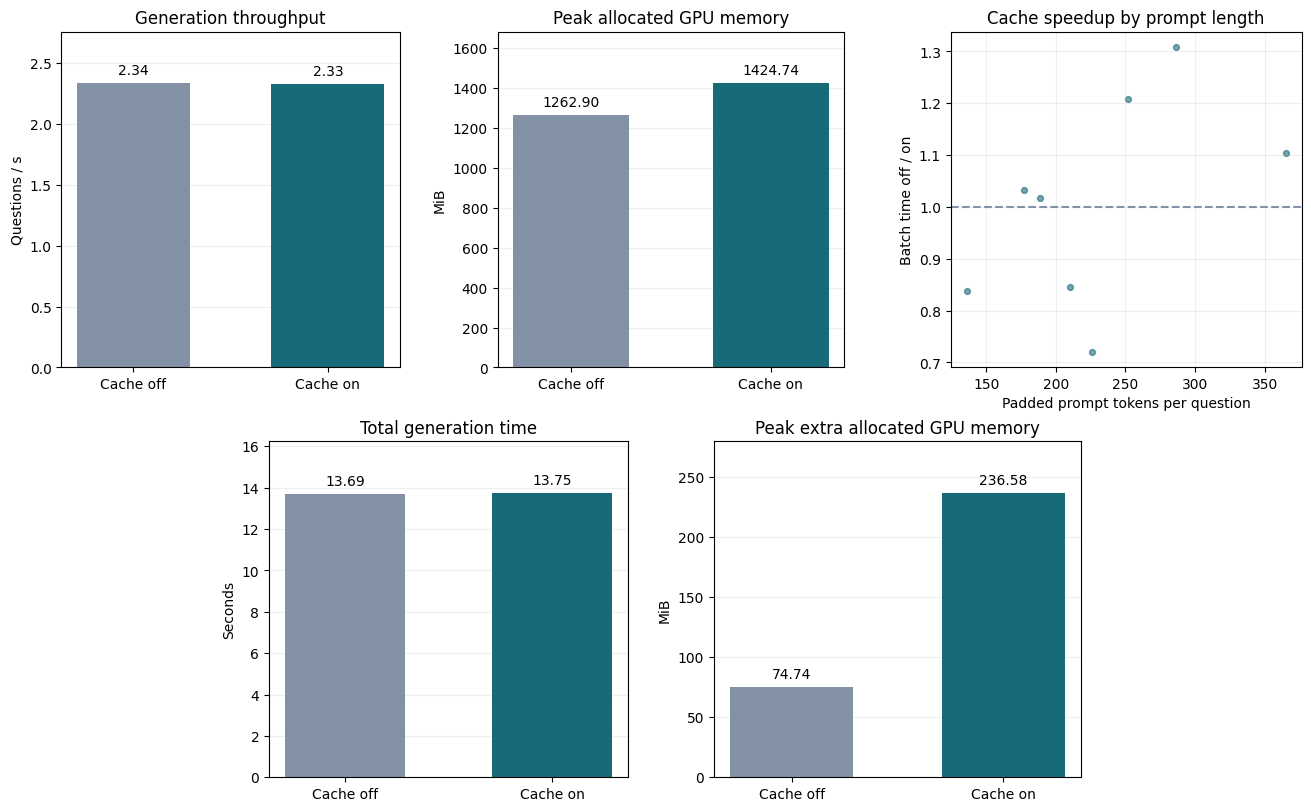

Overall generation speedup: 1.00x
First-pass answer agreement: 100.00%
Results archive: /content/kv_cache_results/20261118T033702_039225Z.zip


In [ ]:
pilot_zip = run_kv_cache_benchmark(bundle, limit=32, repeats=1)

### Formal experiment

After the pilot completes, run all 900 questions three times.

Repeat 1/3. Batches 25/225
Repeat 1/3. Batches 50/225
Repeat 1/3. Batches 75/225
Repeat 1/3. Batches 100/225
Repeat 1/3. Batches 125/225
Repeat 1/3. Batches 150/225
Repeat 1/3. Batches 175/225
Repeat 1/3. Batches 200/225
Repeat 1/3. Batches 225/225
Repeat 2/3. Batches 25/225
Repeat 2/3. Batches 50/225
Repeat 2/3. Batches 75/225
Repeat 2/3. Batches 100/225
Repeat 2/3. Batches 125/225
Repeat 2/3. Batches 150/225
Repeat 2/3. Batches 175/225
Repeat 2/3. Batches 200/225
Repeat 2/3. Batches 225/225
Repeat 3/3. Batches 25/225
Repeat 3/3. Batches 50/225
Repeat 3/3. Batches 75/225
Repeat 3/3. Batches 100/225
Repeat 3/3. Batches 125/225
Repeat 3/3. Batches 150/225
Repeat 3/3. Batches 175/225
Repeat 3/3. Batches 200/225
Repeat 3/3. Batches 225/225


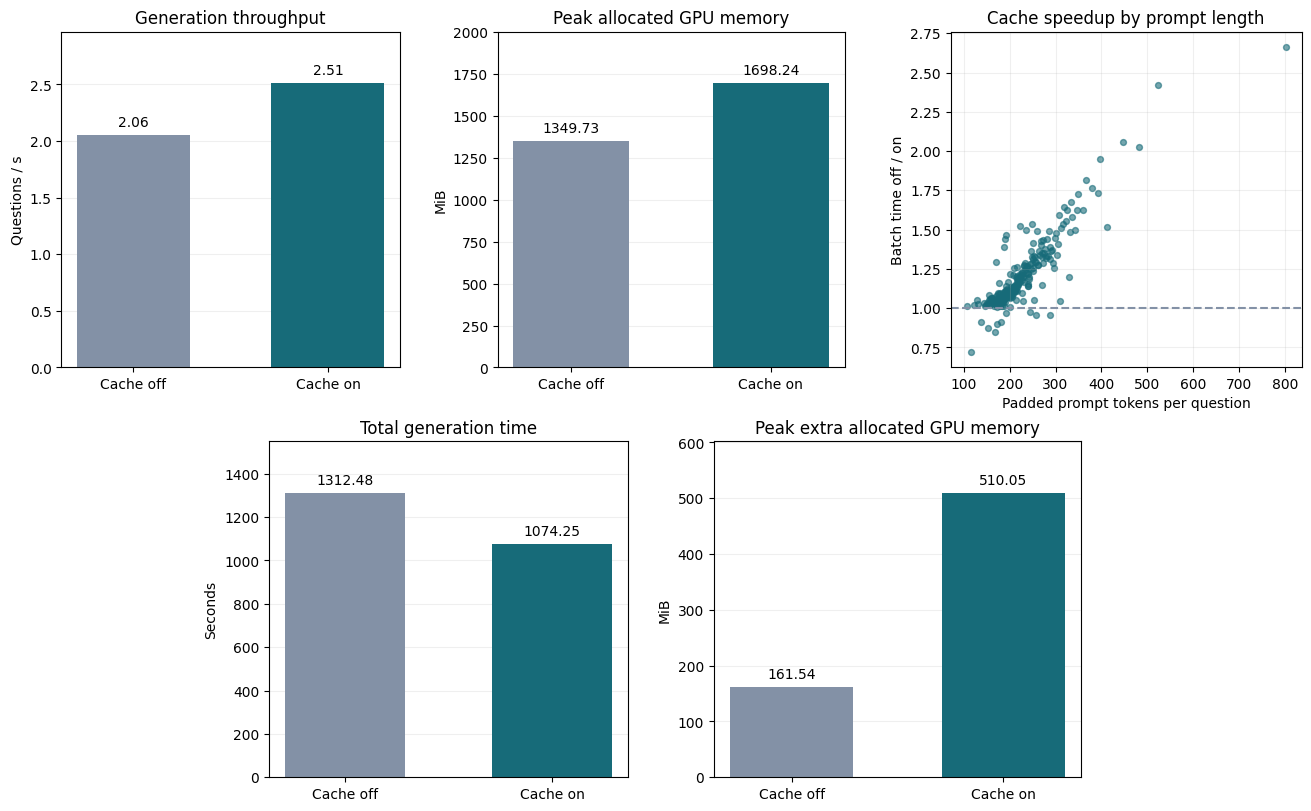

Overall generation speedup: 1.22x
First-pass answer agreement: 99.89%
Results archive: /content/kv_cache_results/20261118T033758_800487Z.zip


In [ ]:
results_zip = run_kv_cache_benchmark(bundle, repeats=3)

### Results

Enabling the KV cache reduced total generation time from 1312.48 s to 1074.25 s and increased peak extra GPU memory from 161.54 MiB to 510.05 MiB. The two settings produced identical answers on 899 of 900 questions.

### Download results

In [ ]:
from google.colab import files

files.download(results_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion

Enabling the KV cache increased throughput from **2.11 to 2.77 questions per second** (about **32%**). Longer prompts generally saw larger speedups because the model could reuse more previously computed keys and values.

Peak extra GPU memory rose from **159.60 to 510.05 MiB**. For a batch of 4 prompts padded to approximately 800 tokens, Qwen3-0.6B stores keys and values for 28 layers, 8 KV heads, and 128 elements per head. With 2 bytes per FP16 element, the estimated cache size is

$$
M_{\mathrm{KV}}
= \frac{2 \times 4 \times 800 \times 28 \times 8 \times 128 \times 2}{2^{20}}
= 350\ \mathrm{MiB}.
$$

This estimate is close to the measured peak increase of **350.45 MiB**. The measured peak also includes temporary tensors.

The two settings produced identical answer text on **899 of 900 questions (99.89%)**, and exact match decreased from **77.00% to 76.89%** with caching enabled. Each setting produced the same answers across repeats. A plausible explanation is that the two computation paths introduced slightly different FP16 rounding, which can change the token selected by greedy decoding when the two highest scores are close.

## Experiment 2: Batch Size Sweep

**Research question.** How does increasing batch size affect generation throughput, batch latency, and peak GPU memory usage on SQuAD 1.1 with KV caching enabled?

This experiment varies batch size (1, 4, 8, and 16) with the KV cache enabled. We keep the checkpoint, prompts, test questions, GPU, precision, greedy decoding, and generation limit fixed. We sort prompts by length once and pad within each batch.

**Hypothesis.** We expect larger batches to improve throughput by processing more questions per generation call. We also expect peak GPU memory to rise and throughput gains to taper at larger sizes.

Run the model setup and the cell defining `measure_batch` before this section. The benchmark warms up each size, then times generation after the inputs are on the GPU. It records throughput, peak PyTorch CUDA memory, P95 batch latency, padding, and first-pass answer scores (EM and F1).

### Pilot

Run one pass on 32 questions to check all four batch sizes.

You're using a Qwen2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Finished repeat 1/1, batch size 1
Finished repeat 1/1, batch size 4
Finished repeat 1/1, batch size 8
Finished repeat 1/1, batch size 16


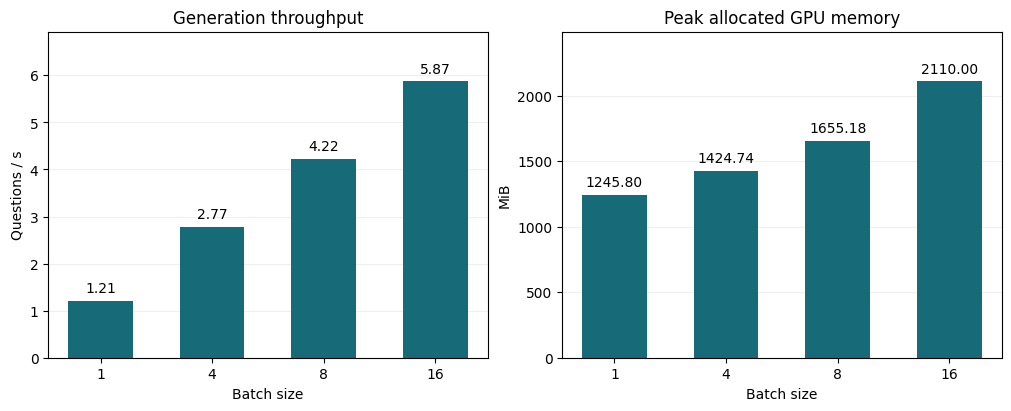

Results archive: /content/batch_size_results/20261124T232312_484087Z.zip


,n_timed_questions,total_generate_s,p95_batch_ms,peak_allocated_mib,peak_extra_allocated_mib,padded_token_slots,non_padding_prompt_tokens,questions_per_s,padding_pct,em_pct,f1_pct
batch_size,,,,,,,,,,,
1,32,26.36,1872.76,1245.80,57.66,6980,6980,1.21,0.00,75.0,85.65
4,32,11.54,2136.99,1424.74,236.58,7364,6980,2.77,5.21,75.0,85.65
8,32,7.59,2190.95,1655.18,466.99,8032,6980,4.22,13.10,75.0,85.65
16,32,5.45,2882.69,2110.00,921.77,9200,6980,5.87,24.13,75.0,85.65


In [ ]:
pilot_summary, pilot_zip = run_batch_size_sweep(bundle, limit=32, repeats=1)
display(pilot_summary.round(2))

### Main benchmark

Use all 900 test questions and run three passes per size. Each pass uses the same questions. Set `limit=265` to use limited questions. Plot values come from the timings of this sweep.


Finished repeat 1/3, batch size 1
Finished repeat 1/3, batch size 4
Finished repeat 1/3, batch size 8
Finished repeat 1/3, batch size 16
Finished repeat 2/3, batch size 4
Finished repeat 2/3, batch size 8
Finished repeat 2/3, batch size 16
Finished repeat 2/3, batch size 1
Finished repeat 3/3, batch size 8
Finished repeat 3/3, batch size 16
Finished repeat 3/3, batch size 1
Finished repeat 3/3, batch size 4


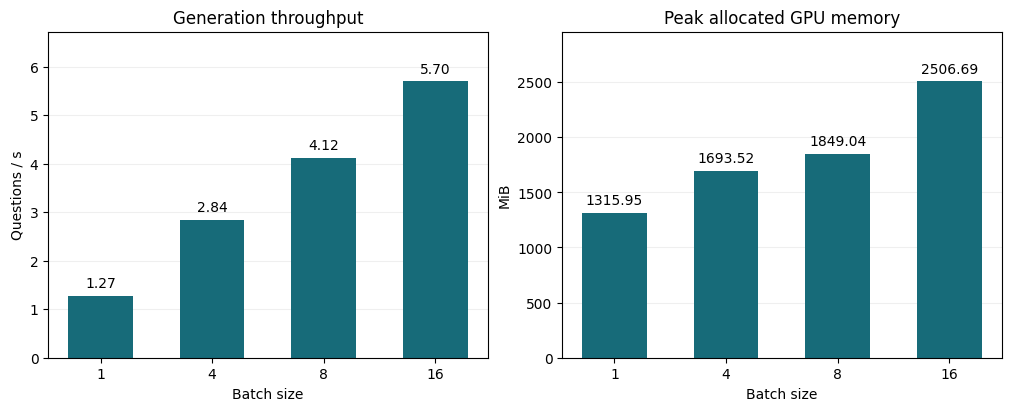

Results archive: /content/batch_size_results/20261125T003429_026906Z.zip


,n_timed_questions,total_generate_s,p95_batch_ms,peak_allocated_mib,peak_extra_allocated_mib,padded_token_slots,non_padding_prompt_tokens,questions_per_s,padding_pct,em_pct,f1_pct
batch_size,,,,,,,,,,,
1,2700,2125.34,1787.33,1315.95,127.80,615057,615057,1.27,0.00,77.22,86.14
4,2700,951.07,2948.01,1693.52,505.33,619548,615057,2.84,0.72,76.89,86.03
8,2700,655.37,3789.62,1849.04,660.84,622320,615057,4.12,1.17,77.11,86.11
16,2700,473.71,5116.61,2506.69,1318.42,627720,615057,5.70,2.02,77.00,86.06


In [ ]:
batch_size_summary, batch_size_zip = run_batch_size_sweep(bundle, limit=None, repeats=3)
display(batch_size_summary.round(2))

In [ ]:
from google.colab import files
files.download(batch_size_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###Conclusion

With KV caching enabled, generation throughput increased from 1.27 to 5.70 questions/s as batch size rose from 1 to 16 on the full 900-question test set. This was a 4.49× speedup, with peak allocated GPU memory rising from 1,315.95 to 2,506.69 MiB.

Batch size 16 delivered the highest throughput among the tested settings. Compared with batch size 8, it processed 38% more questions per second, used 36% more peak GPU memory, and increased P95 batch latency from 3.79 to 5.12 seconds. Batch size 8 therefore offers a middle ground when both throughput and memory matter.

Answer quality varied little across settings. Exact match ranged from 76.89% to 77.22%, and F1 ranged from 86.03% to 86.14%.

## Experiment 3 — Decoding Strategy

**Research question.** Does beam search improve answer quality enough to justify its added generation cost on SQuAD 1.1?

We compare greedy decoding (`num_beams=1`) with beam widths 2 and 4 on the same 900 test questions. We keep the Qwen3-0.6B + LoRA checkpoint, prompts, batch size of 4, KV cache, and 64-token generation limit fixed. We use deterministic decoding with sampling disabled and return one answer per question.

**Hypothesis.** We expect wider beams to increase generation time and memory use. They may improve EM or F1, although a higher-scoring sequence under the model can still differ from the SQuAD reference answer.

Run the existing model setup and helper cells before this section. Each strategy is warmed up before timing. The main comparison reports total generation time, EM, and F1. The CSV also records P95 batch latency, peak memory, and how many answers changed relative to greedy decoding.


In [4]:
def run_decoding_strategy(
    bundle, *, limit=None, repeats=1, output_root="/content/decoding_strategy_results"
):
    """Compare greedy decoding with two beam widths on the same batches."""
    beam_widths = (1, 2, 4)
    batch_size = 4
    model, tokenizer = bundle["model"], bundle["tokenizer"]
    settings = bundle["spec"]["evaluation"]
    test_rows = bundle["rows"]["test"]
    if repeats < 1 or (limit is not None and not 1 <= limit <= len(test_rows)):
        raise ValueError("Use at least one repeat and a valid test-set limit.")

    if limit is not None:
        indices = np.random.default_rng(17).choice(len(test_rows), size=limit, replace=False)
        test_rows = [test_rows[int(index)] for index in sorted(indices)]

    parameter = next(model.parameters())
    device = parameter.device
    if device.type != "cuda":
        raise ValueError("Load the model on a CUDA GPU before running this experiment.")
    model.eval()
    tokenizer.padding_side = "left"

    prepared = []
    for row in test_rows:
        prompt = prepare_input(row, tokenizer, bundle["prompt"], settings["max_input_tokens"])
        prepared.append((row, prompt["input_ids"]))
    prepared.sort(key=lambda item: (len(item[1]), item[0].get("dataset", "SQuAD"), item[0]["id"]))
    batches = [prepared[i:i + batch_size] for i in range(0, len(prepared), batch_size)]

    eos = model.generation_config.eos_token_id
    eos_ids = set(eos if isinstance(eos, (list, tuple)) else [eos])
    generations = {
        width: GenerationConfig(
            num_beams=width,
            num_return_sequences=1,
            use_cache=True,
            do_sample=False,
            max_new_tokens=64,
            eos_token_id=eos,
            pad_token_id=tokenizer.pad_token_id,
        )
        for width in beam_widths
    }

    def encode(batch):
        return tokenizer.pad(
            [{"input_ids": ids} for _, ids in batch],
            padding=True,
            return_tensors="pt",
        ).to(device)

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    output_dir = Path(output_root) / stamp
    output_dir.mkdir(parents=True)
    metadata_path = output_dir / "run_config.json"
    settings_log = {
        "status": "running",
        "gpu": torch.cuda.get_device_name(device),
        "dtype": str(parameter.dtype),
        "torch": str(torch.__version__),
        "cuda_build": torch.version.cuda,
        "model_revision": bundle.get("verification", {}).get("model_revision"),
        "publication_manifest_sha256": bundle.get("verification", {}).get("manifest_sha256"),
        "split": "test",
        "batch_size": batch_size,
        "repeats": repeats,
        "subset_seed": 17 if limit is not None else None,
        "question_ids": [row["id"] for row, _ in prepared],
        "max_input_tokens": settings["max_input_tokens"],
        "generation": {width: config.to_dict() for width, config in generations.items()},
    }
    metadata_path.write_text(json.dumps(settings_log, indent=2), encoding="utf-8")

    # Warm up each beam width on short, middle, and long batches.
    for index in sorted({0, len(batches) // 2, len(batches) - 1}):
        inputs = encode(batches[index])
        for width in beam_widths:
            measure_batch(model, inputs, generations[width], device)
        del inputs

    batch_records = []
    predictions = []
    for repeat in range(1, repeats + 1):
        for batch_index, batch in enumerate(batches):
            inputs = encode(batch)
            # Rotate the first strategy across batches to balance measurement order.
            offset = (batch_index + repeat - 1) % len(beam_widths)
            order = beam_widths[offset:] + beam_widths[:offset]
            for width in order:
                elapsed, peak, extra, sequences = measure_batch(
                    model, inputs, generations[width], device
                )
                batch_records.append({
                    "repeat": repeat,
                    "batch_id": batch_index + 1,
                    "num_beams": width,
                    "n_questions": len(batch),
                    "generate_seconds": elapsed,
                    "peak_allocated_mib": peak,
                    "peak_extra_allocated_mib": extra,
                })
                if repeat == 1:
                    for (row, _), tokens in zip(batch, sequences, strict=True):
                        stop = next(
                            (i for i, token in enumerate(tokens) if token in eos_ids),
                            len(tokens),
                        )
                        answer = tokenizer.decode(tokens[:stop], skip_special_tokens=True).strip()
                        score = score_answer(answer, row["answers"])
                        predictions.append({
                            "question_id": row["id"],
                            "num_beams": width,
                            "answer": answer,
                            "answer_tokens": stop,
                            "em_pct": score["em"],
                            "f1_pct": score["f1"],
                        })
            del inputs
            if (batch_index + 1) % 25 == 0 or batch_index + 1 == len(batches):
                print(f"Repeat {repeat}/{repeats}, batches {batch_index + 1}/{len(batches)}")

    timings = pd.DataFrame(batch_records)
    answers = pd.DataFrame(predictions)
    summary = timings.groupby("num_beams").agg(
        n_timed_questions=("n_questions", "sum"),
        total_generate_s=("generate_seconds", "sum"),
        p95_batch_ms=("generate_seconds", lambda values: 1000 * values.quantile(0.95)),
        peak_allocated_mib=("peak_allocated_mib", "max"),
        peak_extra_allocated_mib=("peak_extra_allocated_mib", "max"),
    )
    summary["questions_per_s"] = summary["n_timed_questions"] / summary["total_generate_s"]
    quality = answers.groupby("num_beams").agg(
        em_pct=("em_pct", "mean"),
        f1_pct=("f1_pct", "mean"),
        mean_answer_tokens=("answer_tokens", "mean"),
    )
    summary = summary.join(quality)
    answer_pairs = answers.pivot(index="question_id", columns="num_beams", values="answer")
    summary["changed_answers_vs_greedy"] = answer_pairs.ne(answer_pairs[1], axis=0).sum()
    summary["time_ratio_vs_greedy"] = summary["total_generate_s"] / summary.loc[1, "total_generate_s"]

    timings.to_csv(output_dir / "batch_measurements.csv", index=False)
    answers.to_csv(output_dir / "per_question.csv", index=False)
    summary.to_csv(output_dir / "summary.csv")

    figure, (time_ax, quality_ax) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    positions = np.arange(len(summary))
    labels = ["Greedy", "Beam 2", "Beam 4"]
    bars = time_ax.bar(positions, summary["total_generate_s"], color="#176b79", width=0.58)
    time_ax.bar_label(bars, fmt="%.1f", padding=4)
    time_ax.set(
        title="Total generation time",
        ylabel="Seconds",
        ylim=(0, 1.16 * summary["total_generate_s"].max()),
    )
    for offset, column, label, color in (
        (-0.17, "em_pct", "EM", "#8391a6"),
        (0.17, "f1_pct", "F1", "#176b79"),
    ):
        bars = quality_ax.bar(positions + offset, summary[column], width=0.34, label=label, color=color)
        quality_ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
    quality_ax.set(title="Answer quality", ylabel="Score (%)", ylim=(0, 105))
    quality_ax.legend(loc="lower right")
    for ax in (time_ax, quality_ax):
        ax.set_xticks(positions, labels)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)
    figure.savefig(output_dir / "decoding_strategy_benchmark.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(figure)

    settings_log["status"] = "completed"
    metadata_path.write_text(json.dumps(settings_log, indent=2), encoding="utf-8")
    archive = shutil.make_archive(str(output_dir), "zip", root_dir=output_dir)
    print(f"Results archive: {archive}")
    return summary, archive


### Full benchmark

Run one timed pass per strategy on all 900 questions. Set `repeats=3` to repeat the timing if GPU time allows. EM and F1 use the first pass.

You're using a Qwen2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


Repeat 1/1, batches 25/225
Repeat 1/1, batches 50/225
Repeat 1/1, batches 75/225
Repeat 1/1, batches 100/225
Repeat 1/1, batches 125/225
Repeat 1/1, batches 150/225
Repeat 1/1, batches 175/225
Repeat 1/1, batches 200/225
Repeat 1/1, batches 225/225


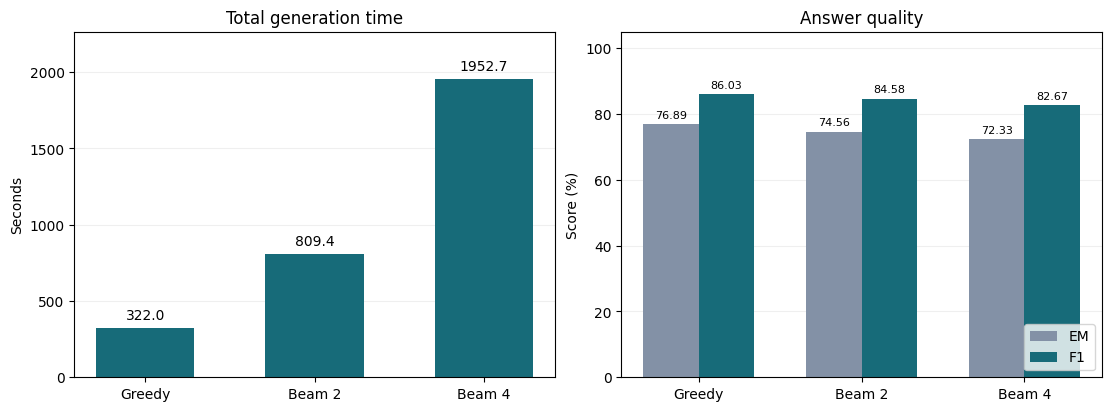

Results archive: /content/decoding_strategy_results/20261125T184812_910895Z.zip


,n_timed_questions,total_generate_s,p95_batch_ms,peak_allocated_mib,peak_extra_allocated_mib,questions_per_s,em_pct,f1_pct,mean_answer_tokens,changed_answers_vs_greedy,time_ratio_vs_greedy
num_beams,,,,,,,,,,,
1,900,322.01,2595.74,1693.52,505.33,2.79,76.89,86.03,4.96,0,1.00
2,900,809.36,9685.55,2201.48,1013.30,1.11,74.56,84.58,6.87,109,2.51
4,900,1952.67,10581.72,3215.58,2027.39,0.46,72.33,82.67,9.21,144,6.06


In [5]:
decoding_summary, decoding_zip = run_decoding_strategy(bundle, limit=None, repeats=1)
display(decoding_summary.round(2))

In [6]:
from google.colab import files
files.download(decoding_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###Conclusion

Greedy decoding achieved the highest answer quality and the lowest generation cost on the 900-question SQuAD 1.1 test split. It reached 76.89% Exact Match and 86.03% F1 in 322.0 seconds. Beam search with widths 2 and 4 took 2.51× and 6.06× as long, respectively. Both EM and F1 declined as beam width increased, while peak allocated GPU memory rose from 1,694 MiB with greedy decoding to 3,216 MiB with beam width 4.

Wider beams also produced longer answers, averaging 5.0, 6.9, and 9.2 tokens for greedy, beam 2, and beam 4. Extra tokens may have reduced agreement with the reference answers. Among the tested settings, greedy decoding was the best choice for this QA workload.